# TripGenie — Model Evaluation

## 1. Evaluate retrieval and preference agreement honestly
There are no observed user ratings or interactions. We evaluate metadata-derived **weak-label** interest retrieval and **synthetic-profile** preference agreement. Neither is an estimate of real user satisfaction or held-out recommendation accuracy.

The reusable evaluator is `backend/evaluation.py`; reproduce the saved report with `python -m backend.evaluation --output docs/evaluation` from the repository root. Original and processed data remain unchanged.

In [1]:
from pathlib import Path
import sys, hashlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data/processed/india_tourism_processed.json").is_file())
if str(root) not in sys.path: sys.path.insert(0, str(root))
from backend.evaluation import run_evaluation
source = root / "data/processed/india_tourism_processed.json"
before = hashlib.sha256(source.read_bytes()).hexdigest()
retrieval, preferences, summary = run_evaluation(source, seed=42)
print(f"Evaluated {summary['masked_interest_queries']} interest queries and {summary['destination_profiles']} distinct-name profiles.")

Evaluated 20 interest queries and 93 distinct-name profiles.


## 2. Weak-label interest retrieval and a masked-text ablation
For tags present in at least five distinct destination names, query an interest phrase and use source tags as binary relevance targets. Group source tags by normalized destination name to avoid double-counting variants. Compare full content, masked content, popularity, and seeded random retrieval.

**Masked content** rebuilds TF-IDF from attraction, activity, experience, culture, and food descriptions, excluding direct `trip_types`, place names, and geography fields. Descriptive language may still reveal tags, so this reduces direct label leakage rather than establishing an independent test set. Full-content scores explicitly include their target tags.

Report precision@5 (hits divided by five), recall@5 (hits divided by relevant names), AP@5 (precision at relevant ranks summed and divided by `min(5, relevant_count)`), and binary nDCG@5 (discounted gain divided by ideal gain). MAP@5 below is mean AP@5 across queries. Missing returned slots count as misses.

,precision_at_5,recall_at_5,MAP@5,ndcg_at_5
method,,,,
full_content,0.88,0.471,0.846,0.891
masked_content,0.54,0.284,0.440,0.545
popularity,0.14,0.043,0.100,0.149
seeded_random,0.11,0.048,0.058,0.108


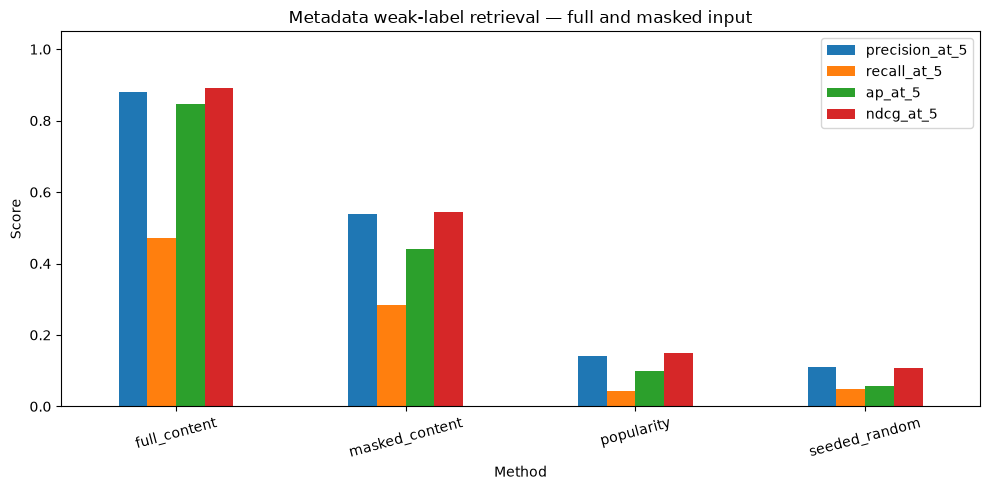

**Observation.** Masked content precision@5 is 0.540, compared with 0.110 for seeded random retrieval. Removing direct label fields changes the task; these values are not user preference accuracy.

In [2]:
retrieval_means = retrieval.groupby("method")[["precision_at_5", "recall_at_5", "ap_at_5", "ndcg_at_5"]].mean()
display(retrieval_means.rename(columns={"ap_at_5":"MAP@5"}).round(3))
fig, ax = plt.subplots(figsize=(10, 5))
retrieval_means.plot.bar(ax=ax, rot=15)
ax.set(title="Metadata weak-label retrieval — full and masked input", ylabel="Score", xlabel="Method", ylim=(0, 1.05))
fig.tight_layout(); plt.show()
display(Markdown(f"**Observation.** Masked content precision@5 is {retrieval_means.loc['masked_content', 'precision_at_5']:.3f}, compared with {retrieval_means.loc['seeded_random', 'precision_at_5']:.3f} for seeded random retrieval. Removing direct label fields changes the task; these values are not user preference accuracy."))

## 3. Personalized preference agreement and graded nDCG
Create one profile for each of 93 distinct names using a representative entry's first two interest tags, budget midpoint, ideal duration, and the first matching best season that does not match an avoid label. A season is omitted when none can be recognized. These are catalogue-derived test cases, not real travelers.

Grade each candidate using mean interest coverage, upper-end budget fit, recommended-duration-range fit, and season match when present. Use `2^gain − 1` discounted by `log2(rank + 1)` for nDCG@5. The ideal ranking uses the best grade per candidate name across its variants; actual ranking grades the returned variant. Selected names are excluded from both candidates and ideal ranking.

The hybrid uses these same metadata signals, so preference agreement is a design/consistency measure. It is not independent validation or evidence that default weights are optimal. No learned collaborative model is introduced.

,ndcg_at_5,preference_agreement,interest_coverage,budget_upper_fit,season_fit,duration_range_fit,region_diversity
method,,,,,,,
content,0.668,0.474,0.481,0.140,0.426,0.819,0.499
hybrid,0.866,0.603,0.496,0.265,0.900,0.886,0.484
popularity,0.504,0.387,0.111,0.256,0.196,0.873,0.211


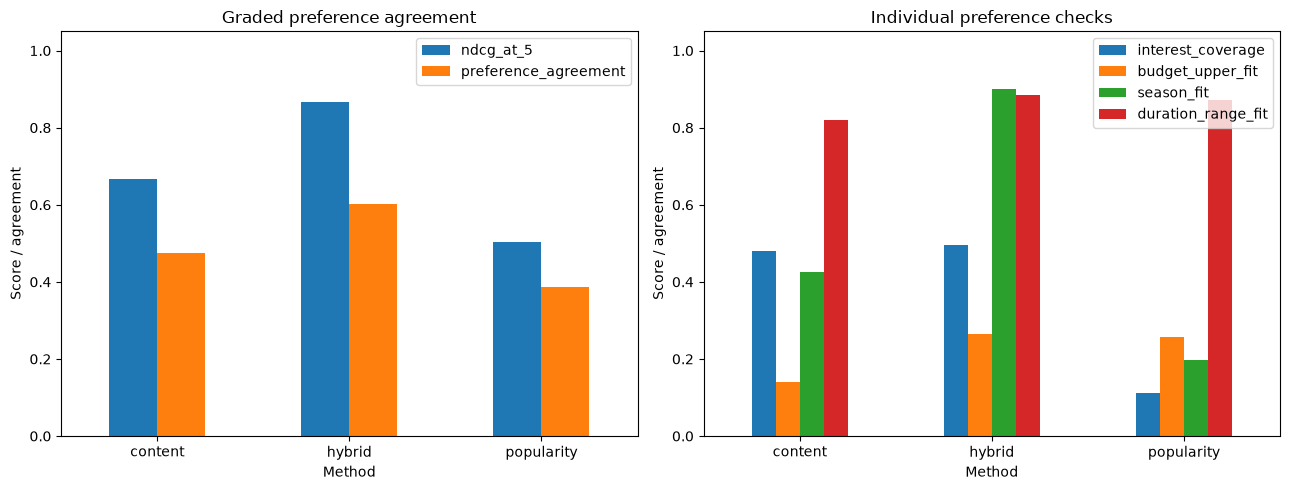

**Observation.** Hybrid preference nDCG@5 is 0.866; content-only is 0.668. Consult each preference metric: overall improvement need not imply every individual criterion improves.

In [3]:
columns = ["ndcg_at_5", "preference_agreement", "interest_coverage", "budget_upper_fit", "season_fit", "duration_range_fit", "region_diversity"]
means = preferences.groupby("method")[columns].mean()
display(means.round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
means[["ndcg_at_5", "preference_agreement"]].plot.bar(ax=axes[0], rot=0)
means[["interest_coverage", "budget_upper_fit", "season_fit", "duration_range_fit"]].plot.bar(ax=axes[1], rot=0)
for ax in axes: ax.set(ylabel="Score / agreement", xlabel="Method", ylim=(0, 1.05))
axes[0].set_title("Graded preference agreement"); axes[1].set_title("Individual preference checks")
fig.tight_layout(); plt.show()
display(Markdown(f"**Observation.** Hybrid preference nDCG@5 is {means.loc['hybrid', 'ndcg_at_5']:.3f}; content-only is {means.loc['content', 'ndcg_at_5']:.3f}. Consult each preference metric: overall improvement need not imply every individual criterion improves."))

## 4. Diversity, coverage, exclusion, and latency
Region diversity is the number of distinct region labels in each top five divided by five. Coverage is the fraction of unique destination names served across all profile queries. Count repeated names and selected-name recommendations explicitly. Report p50/p95 warm-model latency for sequential local calls; this is not a concurrent production load test.

,duplicate_count,self_count,returned_count
method,,,
content,0.0,0.0,5.0
hybrid,0.0,0.0,5.0
popularity,0.0,0.0,5.0


,Catalogue coverage
content,0.989247
hybrid,0.860215
popularity,0.064516


,p50,p95
Method,,
content,2.16,2.37
hybrid,5.48,5.83
popularity,0.47,0.51


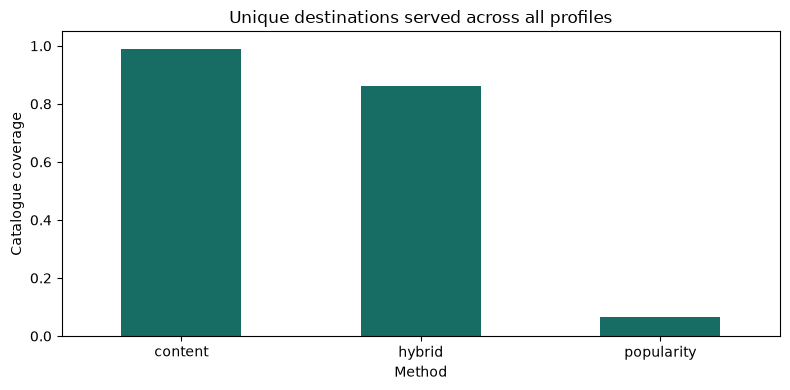

**Observation.** All evaluated methods returned five results per profile, with zero duplicate-name and selected-name violations. Coverage and timing are measured above; popularity-only retrieval repeatedly exposes a small part of the catalogue.

In [4]:
display(preferences.groupby("method")[["duplicate_count", "self_count", "returned_count"]].mean())
display(pd.Series(summary["catalogue_coverage"], name="Catalogue coverage").to_frame())
display(pd.DataFrame(summary["latency_ms"]).T.rename_axis("Method").round(2))
fig, ax = plt.subplots(figsize=(8, 4))
pd.Series(summary["catalogue_coverage"]).plot.bar(ax=ax, rot=0, color="#176D63")
ax.set(title="Unique destinations served across all profiles", ylabel="Catalogue coverage", xlabel="Method", ylim=(0, 1.05))
fig.tight_layout(); plt.show()
assert preferences.duplicate_count.eq(0).all() and preferences.self_count.eq(0).all()
assert hashlib.sha256(source.read_bytes()).hexdigest() == before
display(Markdown("**Observation.** All evaluated methods returned five results per profile, with zero duplicate-name and selected-name violations. Coverage and timing are measured above; popularity-only retrieval repeatedly exposes a small part of the catalogue."))

## 5. Conclusions and next steps
The report provides reproducible retrieval comparisons, preference agreement, coverage/diversity, score invariants, and local latency. Saved CSVs and JSON in `docs/evaluation/` retain query-level results and input checksum. Add independent expert judgments or consented interaction outcomes before tuning or claiming user relevance. Review season interpretation and inconsistent source variants, and measure latency under a realistic deployment load. These evaluations use no invented user ratings.